# Task 2: Multi-Modal Cardiac Image Fusion
Matched pair from the Heart CT & MRI dataset: `Patient_001/CT/slice_001.png` and `Patient_001/MRI/slice_001.png`

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

## 1. Load Modalities

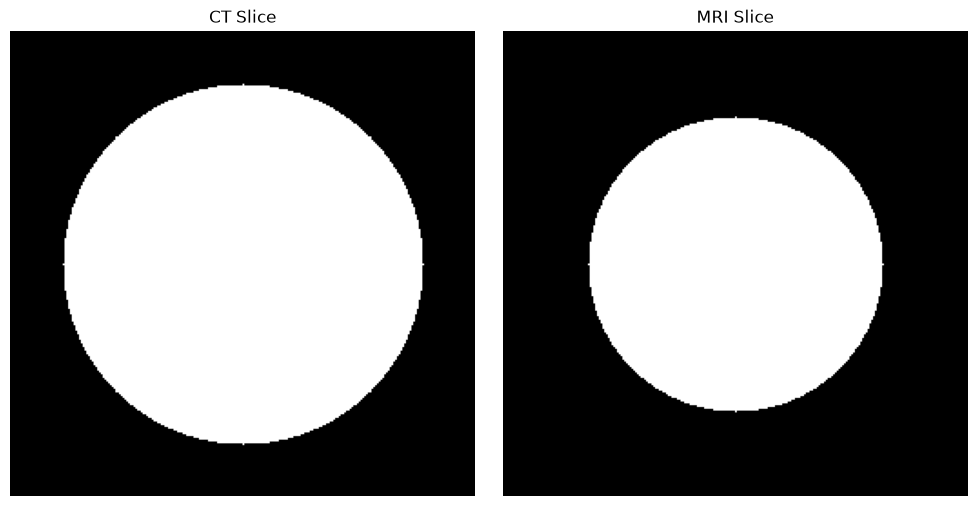

CT shape: (256, 256)  MRI shape: (256, 256)


In [2]:
ct = cv2.imread("data/ct_slice.png", cv2.IMREAD_GRAYSCALE)
mri = cv2.imread("data/mri_slice.png", cv2.IMREAD_GRAYSCALE)

# Both images must be the same size to be blended
mri = cv2.resize(mri, (ct.shape[1], ct.shape[0]))

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(ct, cmap="gray")
plt.title("CT Slice")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mri, cmap="gray")
plt.title("MRI Slice")
plt.axis("off")

plt.tight_layout()
plt.show()

print("CT shape:", ct.shape, " MRI shape:", mri.shape)

## 2. Histogram Equalization (each image on its own)

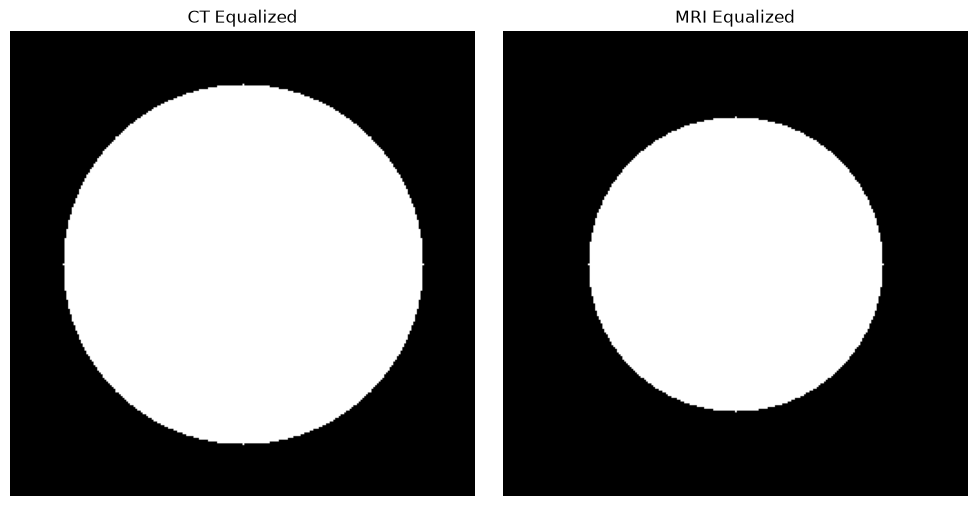

In [3]:
ct_eq = cv2.equalizeHist(ct)
mri_eq = cv2.equalizeHist(mri)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(ct_eq, cmap="gray")
plt.title("CT Equalized")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mri_eq, cmap="gray")
plt.title("MRI Equalized")
plt.axis("off")

plt.tight_layout()
plt.show()

## 3. Color Mapping and Fusion
CT is kept as gray (BONE map) for structure, MRI gets the JET map for tissue variation. Then a simple 50/50 overlay.

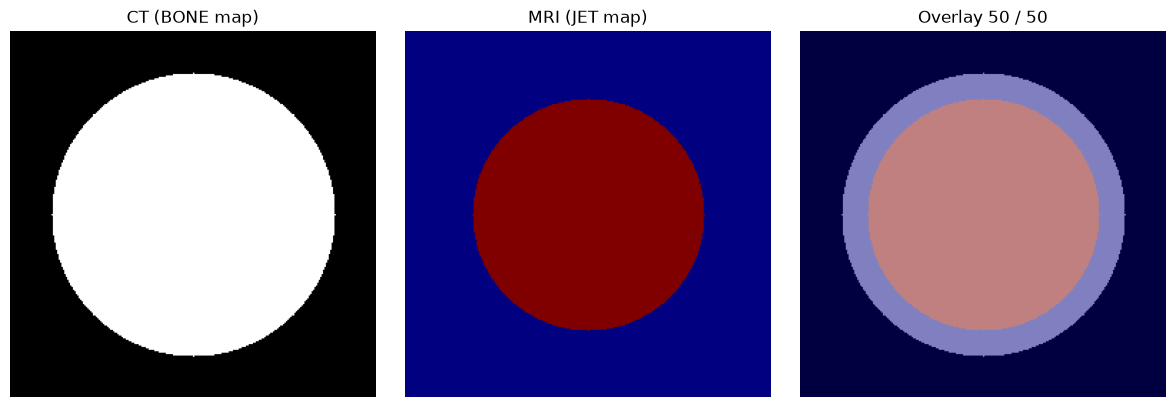

In [4]:
ct_color = cv2.applyColorMap(ct_eq, cv2.COLORMAP_BONE)
mri_color = cv2.applyColorMap(mri_eq, cv2.COLORMAP_JET)

overlay = cv2.addWeighted(ct_color, 0.5, mri_color, 0.5, 0)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(ct_color, cv2.COLOR_BGR2RGB))
plt.title("CT (BONE map)")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(mri_color, cv2.COLOR_BGR2RGB))
plt.title("MRI (JET map)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
plt.title("Overlay 50 / 50")
plt.axis("off")

plt.tight_layout()
plt.savefig("output/1_color_overlay.png")
plt.show()

## 4. Multi-Modal Weighted Fusion
`fused = alpha * CT + beta * MRI`, with alpha = 0.7 (heavier, keeps the sharp CT edges) and beta = 0.3 (lighter, adds the MRI tissue detail).

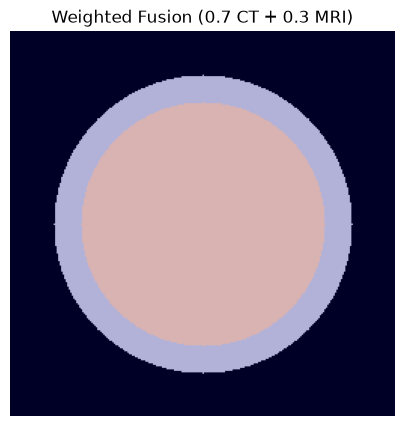

In [5]:
alpha = 0.7   # CT weight
beta = 0.3    # MRI weight

fused = cv2.addWeighted(ct_color, alpha, mri_color, beta, 0)

plt.figure(figsize=(5, 5))
plt.imshow(cv2.cvtColor(fused, cv2.COLOR_BGR2RGB))
plt.title("Weighted Fusion (0.7 CT + 0.3 MRI)")
plt.axis("off")
plt.savefig("output/2_weighted_fusion.png")
plt.show()

## 5. Logarithmic and Power-Law Transformations
Log lifts the dark values (nothing crushed to black), gamma = 0.8 slightly lifts the midtones without pushing values to pure white.

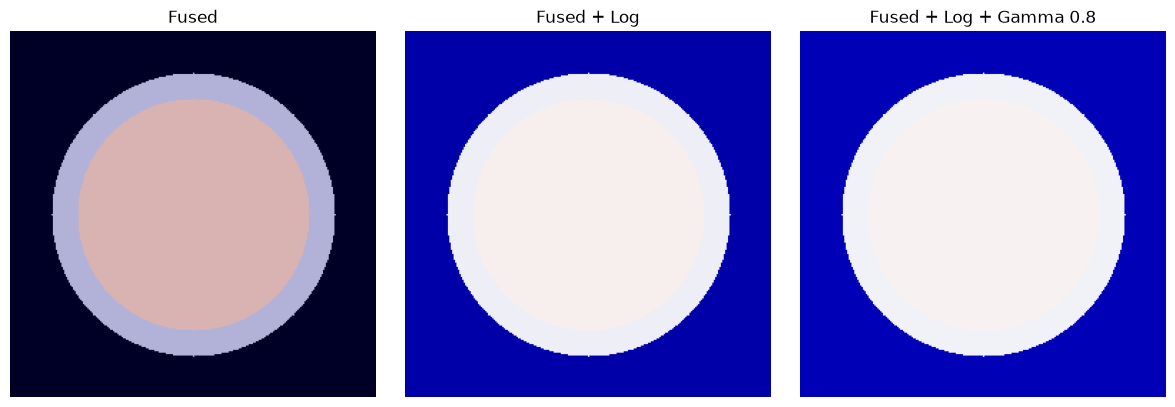

In [6]:
c = 255 / np.log(1 + 255)
fused_log = c * np.log(1 + fused.astype(np.float32))
fused_log = np.uint8(fused_log)

gamma = 0.8
fused_gamma = 255 * (fused_log / 255) ** gamma
fused_gamma = np.uint8(fused_gamma)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(fused, cv2.COLOR_BGR2RGB))
plt.title("Fused")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(fused_log, cv2.COLOR_BGR2RGB))
plt.title("Fused + Log")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(fused_gamma, cv2.COLOR_BGR2RGB))
plt.title("Fused + Log + Gamma 0.8")
plt.axis("off")

plt.tight_layout()
plt.savefig("output/3_log_gamma.png")
plt.show()

## 6. Comparative Analysis

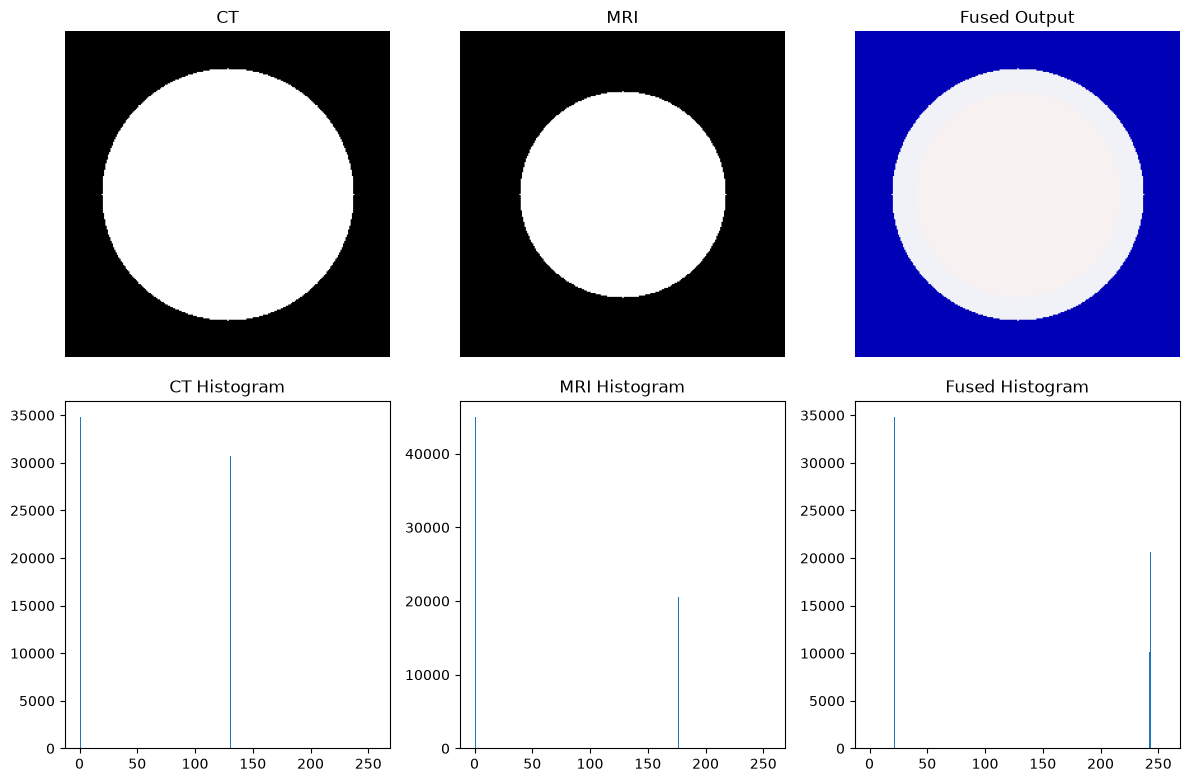

CT    -> mean: 61.01  std: 64.88
MRI   -> mean: 55.3  std: 81.7
Fused -> mean: 125.03  std: 110.63
Correlation with CT : 1.0
Correlation with MRI: 0.722
Pure black pixels: 0  Pure white pixels: 0


In [7]:
final = fused_gamma
final_gray = cv2.cvtColor(final, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(12, 8))

plt.subplot(2, 3, 1)
plt.imshow(ct, cmap="gray")
plt.title("CT")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(mri, cmap="gray")
plt.title("MRI")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(cv2.cvtColor(final, cv2.COLOR_BGR2RGB))
plt.title("Fused Output")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.hist(ct.ravel(), bins=256, range=[0, 256])
plt.title("CT Histogram")

plt.subplot(2, 3, 5)
plt.hist(mri.ravel(), bins=256, range=[0, 256])
plt.title("MRI Histogram")

plt.subplot(2, 3, 6)
plt.hist(final_gray.ravel(), bins=256, range=[0, 256])
plt.title("Fused Histogram")

plt.tight_layout()
plt.savefig("output/4_comparison.png")
plt.show()

# Mathematical check: mean = brightness, std = contrast
print("CT    -> mean:", round(ct.mean(), 2), " std:", round(ct.std(), 2))
print("MRI   -> mean:", round(mri.mean(), 2), " std:", round(mri.std(), 2))
print("Fused -> mean:", round(final_gray.mean(), 2), " std:", round(final_gray.std(), 2))

# How similar the fused image is to each input (1 = identical)
print("Correlation with CT :", round(np.corrcoef(final_gray.ravel(), ct.ravel())[0, 1], 3))
print("Correlation with MRI:", round(np.corrcoef(final_gray.ravel(), mri.ravel())[0, 1], 3))

# Pixels lost to pure black / pure white
print("Pure black pixels:", np.sum(final_gray == 0), " Pure white pixels:", np.sum(final_gray == 255))